# Day5 · PPO 从采样到完整训练

沿用 Day4 的两状态环境，把已经讲过的 Actor、Critic、GAE 与 PPO-Clip
接成一个可运行闭环。按单元顺序运行，每段代码上方解释它的输入与作用。
这是教师提供的分段练习，供 RedMoon 阅读、修改和复跑，不声称是独立手写产出。

```text
固定策略采样 32 个完整回合
    -> 按时间顺序计算 GAE
    -> 固定旧概率、优势和 Critic 目标
    -> 同批最多更新 4 轮，每轮重新前向
    -> 用更新后的策略重新采样下一批
    -> 冻结参数评估，完整走到终点
```

一个回合最多两步，所以 32 个回合产生 32 至 64 条转移。
这里先用全批更新看清机制，不加入 mini-batch、并行环境或长期回放池。

## 1. 导入与参数

| 变量 | 含义 |
|---|---|
| `gamma` | 未来奖励折扣，长路线回报为 $0+0.9\times2=1.8$ |
| `lam` | GAE 的误差衰减参数，不是学习率 |
| `episodes_per_batch` | 每批重新采样的完整回合数 |
| `num_updates` | “采样一批，再训练这一批”的外层次数 |
| `update_epochs` | 一批数据最多进行几次参数更新 |
| `clip_eps` | 比值裁剪幅度，不是概率的绝对上下限 |
| `target_kl` | 近似 KL 的停止参考，超过后不再继续本批下一步 |
| `normalize_advantage` | 是否标准化 Actor 权重，默认关闭以保留原始符号 |

本练习沿用 Day4 的外层时间权重 $\gamma^t$；常见 PPO 实现直接按
rollout 样本均值优化，不额外乘它。这里的选择要与前一天的口径区分清楚。

In [1]:
import os

# 只调整当前进程，沿用本项目已有的 Windows 数值库兼容设置。
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import json
import math
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

torch.set_num_threads(1)   # 极小网络在 CPU 上运行即可
gamma, lam = 0.9, 0.95
episodes_per_batch, num_updates, update_epochs = 32, 80, 4
learning_rate, clip_eps = 0.03, 0.2
critic_coef, entropy_coef = 0.5, 0.01
max_grad_norm, target_kl = 0.5, 0.02
normalize_advantage = False
seed, eval_episodes = 7, 500
print("PyTorch:", torch.__version__)
print("每批回合数 / 外层批次数 / 每批最多更新轮数:",
      episodes_per_batch, num_updates, update_epochs)

PyTorch: 2.10.0+cu128
每批回合数 / 外层批次数 / 每批最多更新轮数: 32 80 4


## 2. 环境：先看智能体实际走的路

```text
s0 --动作 0，奖励 0--> s1 --任意动作，奖励 2--> 终点
s0 --动作 1，奖励 1--------------------------> 终点
```

长路线折扣回报为 1.8，短路线为 1.0，两条路线都能终止。
因此“成功到终点”不能单独证明选到了更好的路线，要同时看长路线概率和回报。
`None` 表示没有下一个非终止状态；只能在非终止时把状态送入网络。
本环境没有外部截断，但后面的 GAE 边界检查会单独检验截断处理。

In [2]:
class TinyChainEnv:
    def __init__(self):
        self.n_states = 2
        self.n_actions = 2
        self.current_state = 0

    def reset(self):
        self.current_state = 0
        return self.current_state

    def step(self, action):
        if action not in (0, 1):
            raise ValueError("action 必须是 0 或 1")
        if self.current_state == 0:
            if action == 0:
                next_state, reward, terminated = 1, 0.0, False
            else:
                next_state, reward, terminated = None, 1.0, True
        elif self.current_state == 1:
            next_state, reward, terminated = None, 2.0, True
        else:
            raise RuntimeError("回合已结束，请先 reset()")
        self.current_state = next_state
        return next_state, reward, terminated, {}

env = TinyChainEnv()

## 3. Actor 与 Critic

状态用 one-hot 表示：`s0 -> [1,0]`、`s1 -> [0,1]`。
Actor 返回每个动作的 logits；Critic 返回每个状态的一个价值预测。

为减少这次练习的干扰，两条线性分支不共享参数，与 Day3 的共享主体结构不同。
输入为 `[B,2]`，输出 logits 为 `[B,2]`、values 为 `[B]`。
使用 `squeeze(-1)` 只删除价值输出的最后一维，B=1 时也保留批次维。
两个分支初始化为零：初始动作概率各为 0.5，初始价值为 0，
不把手算中的 1.4 偷填成网络已经学到的结果。

In [3]:
def state_to_tensor(state):
    tensor = torch.zeros((1, 2), dtype=torch.float32)
    tensor[0, state] = 1.0
    return tensor

class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.actor = nn.Linear(2, 2, bias=False)
        self.critic = nn.Linear(2, 1, bias=False)
        nn.init.zeros_(self.actor.weight)
        nn.init.zeros_(self.critic.weight)

    def forward(self, states):
        return self.actor(states), self.critic(states).squeeze(-1)

@torch.no_grad()
def policy_stats(model):
    logits, values = model(torch.eye(2))
    p_long = Categorical(logits=logits).probs[0, 0].item()
    return {"p_long": p_long, "expected_return": 1 + 0.8 * p_long,
            "value_s0": values[0].item(), "value_s1": values[1].item()}

print("初始化:", policy_stats(ActorCritic()))

初始化: {'p_long': 0.5, 'expected_return': 1.4, 'value_s0': 0.0, 'value_s1': 0.0}


## 4. GAE：目标阶段不需要梯度

`rewards[t]` 是实际奖励，`old_values[t]` 是采样时的预测，
`next_values[t]` 是该条转移真实下一状态的采样时预测。
所有数组都是 `[B]`，按采样时间顺序排列。

$$
\delta_t=r_t+\gamma(1-d_t)V_{old}(s_{t+1})-V_{old}(s_t)
$$
$$
\hat A_t=\delta_t+\gamma\lambda(1-e_t)\hat A_{t+1}.
$$

`d_t` 表示真正终止，`e_t` 表示本回合结束并准备 reset。
外部截断时可以有 `d_t=0, e_t=1`：保留最后观测的价值，
但不把新一局的优势接过来。数组末尾没有采到的误差也不累加。

In [4]:
@torch.no_grad()
def compute_gae(rewards, old_values, next_values,
                terminated, episode_ends, gamma=gamma, lam=lam):
    bootstrap_mask = (~terminated).to(rewards.dtype)
    trace_mask = (~episode_ends).to(rewards.dtype)
    deltas = rewards + gamma * bootstrap_mask * next_values - old_values
    advantages = torch.zeros_like(rewards)
    gae = rewards.new_zeros(())
    for t in reversed(range(len(rewards))):
        gae = deltas[t] + gamma * lam * trace_mask[t] * gae
        advantages[t] = gae
    return advantages

# 单独的教学例子：奖励 4，不与训练环境的末步奖励 2 混淆。
example_advantages = compute_gae(
    torch.tensor([0.0, 4.0]), torch.tensor([3.0, 2.0]),
    torch.tensor([2.0, 0.0]), torch.tensor([False, True]),
    torch.tensor([False, True]), gamma=0.9, lam=0.5,
)
print("示例原始 GAE:", example_advantages.tolist())
print("示例 Critic 目标:",
      (torch.tensor([3.0, 2.0]) + example_advantages).tolist())

示例原始 GAE: [-0.30000007152557373, 2.0]
示例 Critic 目标: [2.6999998092651367, 4.0]


## 5. Rollout：用同一个策略采样多个回合

`rollout` 就是一批实际交互经历。采样函数内部没有 `optimizer.step()`，
所以一批数据中的 old probability 都属于同一份参数。

| 保存的字段 | 用途 |
|---|---|
| `states`, `actions` | 当时处于哪个状态、实际执行哪个动作 |
| `rewards` | 环境实际给出的奖励 |
| `old_log_probs` | 实际动作的旧对数概率，后来概率比的固定分母 |
| `old_values`, `next_values` | 计算原始 GAE 的价值快照 |
| `terminated`, `episode_ends` | 分别控制 bootstrap 与跨回合递推 |
| `time_weights` | 每条样本在其原回合中的 $\gamma^t$ |

与 REINFORCE 保存可反传的旧 log_prob 不同，PPO 采样用 `no_grad()`；
训练时会重新前向计算有梯度的 **new** log_prob。

In [5]:
@torch.no_grad()
def collect_batch(model, n_episodes=episodes_per_batch):
    fields = {name: [] for name in (
        "states", "actions", "rewards", "old_log_probs", "old_values",
        "next_values", "terminated", "episode_ends", "time_weights")}
    episode_returns, trajectories = [], []
    for _ in range(n_episodes):
        state = env.reset()
        t, episode_return, trajectory = 0, 0.0, []
        while True:
            state_tensor = state_to_tensor(state)
            logits, value = model(state_tensor)
            dist = Categorical(logits=logits)
            action_tensor = dist.sample()
            action = int(action_tensor.item())
            next_state, reward, terminated, _ = env.step(action)
            next_value = 0.0
            if not terminated:
                _, prediction = model(state_to_tensor(next_state))
                next_value = prediction.item()

            fields["states"].append(state_tensor.squeeze(0))
            fields["actions"].append(action)
            fields["rewards"].append(reward)
            fields["old_log_probs"].append(dist.log_prob(action_tensor).item())
            fields["old_values"].append(value.item())
            fields["next_values"].append(next_value)
            fields["terminated"].append(terminated)
            fields["episode_ends"].append(terminated)  # 本环境没有外部截断
            fields["time_weights"].append(gamma ** t)
            episode_return += (gamma ** t) * reward
            trajectory.append((state, action, reward, next_state, terminated))
            if terminated:
                break
            state = next_state
            t += 1
        episode_returns.append(episode_return)
        trajectories.append(trajectory)

    batch = {"states": torch.stack(fields["states"])}
    for name, entries in fields.items():
        if name == "states":
            continue
        dtype = (torch.long if name == "actions" else torch.bool
                 if name in ("terminated", "episode_ends") else torch.float32)
        batch[name] = torch.tensor(entries, dtype=dtype)
    return batch, episode_returns, trajectories

## 6. 固定目标，并展开真实批次

Critic 目标使用 `old_values + raw_advantages`。
Actor 权重可以单独标准化，但不能用标准化权重改写 Critic 目标。
先算 GAE 再换序；不能先把时间顺序打乱后直接反向递推。

本单元用独立的演示网络采样，打印前八条样本。它不会改变后面的正式训练网络。
初始 Critic 为零且 lambda=0.95，长路线起点的 GAE 为
$0+0.9\times0.95\times2=1.71$，不是完整回报 1.8；
这是当前预测参与构造的 lambda 目标，不是把之前手算的旧价值 1.4 填进网络。

In [6]:
@torch.no_grad()
def prepare_batch(batch):
    raw = compute_gae(
        batch["rewards"], batch["old_values"], batch["next_values"],
        batch["terminated"], batch["episode_ends"],
    )
    batch["raw_advantages"] = raw
    batch["targets"] = (batch["old_values"] + raw).clone()
    weights = raw.clone()
    if normalize_advantage:
        weights = (weights - weights.mean()) / (weights.std(unbiased=False) + 1e-8)
    batch["actor_weights"] = weights
    return batch

torch.manual_seed(seed)
demo_model = ActorCritic()
demo_before_collect = {k: v.detach().clone() for k, v in demo_model.state_dict().items()}
demo_batch, demo_returns, demo_trajectories = collect_batch(demo_model)
demo_after_collect = {k: v.detach().clone() for k, v in demo_model.state_dict().items()}
prepare_batch(demo_batch)
print("回合数 / 转移数:", len(demo_returns), len(demo_batch["actions"]))
print("state action reward old_prob old_value raw_GAE target")
for i in range(min(8, len(demo_batch["actions"]))):
    print(int(demo_batch["states"][i].argmax()), int(demo_batch["actions"][i]),
          f'{demo_batch["rewards"][i]:.1f}',
          f'{demo_batch["old_log_probs"][i].exp():.3f}',
          f'{demo_batch["old_values"][i]:.3f}',
          f'{demo_batch["raw_advantages"][i]:.3f}',
          f'{demo_batch["targets"][i]:.3f}')

回合数 / 转移数: 32 48
state action reward old_prob old_value raw_GAE target
0 0 0.0 0.500 0.000 1.710 1.710
1 1 2.0 0.500 0.000 2.000 2.000
0 0 0.0 0.500 0.000 1.710 1.710
1 1 2.0 0.500 0.000 2.000 2.000
0 0 0.0 0.500 0.000 1.710 1.710
1 0 2.0 0.500 0.000 2.000 2.000
0 1 1.0 0.500 0.000 1.000 1.000
0 1 1.0 0.500 0.000 1.000 1.000


## 7. PPO 损失：当前输出有梯度，旧快照没有梯度

`actions` 不重新采样，而是取出原经历实际动作。
PPO 的两个策略分支取较小值，再取负号作为要最小化的 Actor loss。
Critic loss 使用回报尺度的固定目标，熵奖励鼓励保留动作分布多样性。

初始 ratio=1 只说明网络还没离开采样策略，不代表没有梯度。
`values` 与 `targets` 必须都是 `[B]`，避免 `[B,1]-[B]` 意外广播成 `[B,B]`。

In [7]:
def compute_losses(model, batch):
    logits, values = model(batch["states"])
    dist = Categorical(logits=logits)
    new_log_probs = dist.log_prob(batch["actions"])
    log_ratio = new_log_probs - batch["old_log_probs"]
    ratio = log_ratio.exp()
    raw = ratio * batch["actor_weights"]
    clipped = ratio.clamp(1 - clip_eps, 1 + clip_eps) * batch["actor_weights"]
    actor_loss = -(batch["time_weights"] * torch.minimum(raw, clipped)).mean()
    assert values.shape == batch["targets"].shape
    critic_loss = (values - batch["targets"]).square().mean()
    entropy = dist.entropy().mean()
    loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy
    with torch.no_grad():
        # rollout 中的样本估计，不是全状态精确 KL。
        approx_kl = ((ratio - 1) - log_ratio).mean().item()
        clip_fraction = ((ratio - 1).abs() > clip_eps).float().mean().item()
    metrics = {"actor_loss": actor_loss.item(), "critic_loss": critic_loss.item(),
               "entropy": entropy.item(), "approx_kl": approx_kl,
               "clip_fraction": clip_fraction, "ratio_mean": ratio.mean().item()}
    return loss, metrics

## 8. 一批数据有限更新多轮

`epoch` 是这批数据的优化轮次，不是环境回合。
每轮重新调用模型，建立新图；每次 `backward()` 前清空上轮梯度。
`clip_grad_norm_` 限制梯度整体范数，与 PPO 的概率比 clip 是两种不同裁剪。

如果当前近似 KL 超过参考阈值，停止本批后续更新。
它不是硬约束：检查之后执行的一步仍可能把 KL 推过阈值，估计也有采样误差。
本函数返回每轮日志和批次结束后的指标；每次调用都检查固定张量没有被改写。

In [8]:
def update_batch(model, optimizer, batch, epochs=update_epochs,
                 kl_limit=target_kl):
    fixed_names = ("old_log_probs", "old_values", "raw_advantages",
                   "actor_weights", "targets")
    snapshots = {name: batch[name].clone() for name in fixed_names}
    epoch_logs = []
    stopped_early = False
    for epoch in range(epochs):
        loss, metrics = compute_losses(model, batch)
        if metrics["approx_kl"] > kl_limit:
            stopped_early = True
            break
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()
        epoch_logs.append({"epoch": epoch + 1, **metrics,
                           "p_after": policy_stats(model)["p_long"]})
    with torch.no_grad():
        _, final_metrics = compute_losses(model, batch)
    for name in fixed_names:
        assert torch.equal(batch[name], snapshots[name]), name
    return epoch_logs, final_metrics, stopped_early

demo_loss, demo_initial_metrics = compute_losses(demo_model, demo_batch)
demo_optimizer = torch.optim.Adam(demo_model.parameters(), lr=learning_rate)
demo_logs, demo_final_metrics, demo_stopped = update_batch(
    demo_model, demo_optimizer, demo_batch)
print("初始 ratio 均值:", demo_initial_metrics["ratio_mean"])
for row in demo_logs:
    print(f'epoch={row["epoch"]}, ratio_mean={row["ratio_mean"]:.4f}, '
          f'KL_before={row["approx_kl"]:.5f}, p0_after={row["p_after"]:.4f}')
print("本批更新结束后的指标:", demo_final_metrics)
print("是否提前停止:", demo_stopped)

初始 ratio 均值: 1.0
epoch=1, ratio_mean=1.0000, KL_before=0.00000, p0_after=0.5150
epoch=2, ratio_mean=1.0012, KL_before=0.00045, p0_after=0.5300
epoch=3, ratio_mean=1.0025, KL_before=0.00180, p0_after=0.5449
epoch=4, ratio_mean=1.0037, KL_before=0.00404, p0_after=0.5598
本批更新结束后的指标: {'actor_loss': -1.5405861139297485, 'critic_loss': 2.2789649963378906, 'entropy': 0.6859865784645081, 'approx_kl': 0.007171063218265772, 'clip_fraction': 0.0, 'ratio_mean': 1.004980206489563}
是否提前停止: False


## 9. 完整训练：每个外层循环重新采样

这是训练闭环的入口。外层 80 批，每批采样 32 回合，
每批最多更新 4 次；三个数字对应三个不同单位。

`sample_return` 来自本批更新前采到的路线；
`expected_return` 来自更新后策略的精确期望 $1+0.8p$。
两者时间点与含义不同，不能要求逐批完全相等。

In [9]:
torch.manual_seed(seed)
model = ActorCritic()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
initial_stats = policy_stats(model)
history = []
total_episodes = total_steps = total_optimizer_steps = 0
for update in range(num_updates):
    batch, sampled_returns, trajectories = collect_batch(model)
    prepare_batch(batch)       # 只在优化本批之前计算一次
    epoch_logs, metrics, stopped = update_batch(model, optimizer, batch)
    total_episodes += len(sampled_returns)
    total_steps += len(batch["actions"])
    total_optimizer_steps += len(epoch_logs)
    stats = policy_stats(model)
    history.append({"update": update + 1, **stats, **metrics,
                    "sample_return": sum(sampled_returns) / len(sampled_returns),
                    "optimizer_steps": len(epoch_logs), "stopped_early": stopped})
    if update == 0 or (update + 1) % 20 == 0:
        print(f'batch={update + 1:2d}, p0={stats["p_long"]:.4f}, '
              f'V(s0)={stats["value_s0"]:.4f}, '
              f'J={stats["expected_return"]:.4f}, '
              f'epochs={len(epoch_logs)}, KL={metrics["approx_kl"]:.5f}')
final_stats = policy_stats(model)
print("实际回合数 / 环境步数 / 参数更新次数:",
      total_episodes, total_steps, total_optimizer_steps)

batch= 1, p0=0.5598, V(s0)=0.1200, J=1.4478, epochs=4, KL=0.00717
batch=20, p0=0.9651, V(s0)=1.7903, J=1.7721, epochs=4, KL=0.00039
batch=40, p0=0.9914, V(s0)=1.7965, J=1.7931, epochs=4, KL=0.00001
batch=60, p0=0.9954, V(s0)=1.7933, J=1.7963, epochs=4, KL=0.00002
batch=80, p0=0.9969, V(s0)=1.7946, J=1.7975, epochs=4, KL=0.00001
实际回合数 / 环境步数 / 参数更新次数: 2560 4997 320


## 10. 冻结评估：真的走完，不再训练

评估时没有 `backward()` 或 `optimizer.step()`。
采样评估使用 `sample()`，所以冻结策略仍可能走不同路线；
贪心评估使用 `argmax()`，观察最偏好的完整路线。
改用独立评估种子，且比较评估前后的每一份参数。

In [10]:
@torch.no_grad()
def evaluate_episode(model, greedy=False):
    state = env.reset()
    trajectory, discounted_return, t = [], 0.0, 0
    while True:
        logits, _ = model(state_to_tensor(state))
        action = (int(logits.argmax(dim=-1).item()) if greedy else
                  int(Categorical(logits=logits).sample().item()))
        next_state, reward, terminated, _ = env.step(action)
        trajectory.append((state, action, reward, next_state, terminated))
        discounted_return += (gamma ** t) * reward
        if terminated:
            return discounted_return, trajectory
        state = next_state
        t += 1

model.eval()
before_eval = {k: v.detach().clone() for k, v in model.state_dict().items()}
torch.manual_seed(2026)
eval_results = [evaluate_episode(model) for _ in range(eval_episodes)]
eval_long_count = sum(path[0][1] == 0 for _, path in eval_results)
eval_mean = sum(value for value, _ in eval_results) / eval_episodes
greedy_return, greedy_trajectory = evaluate_episode(model, greedy=True)
print(f'长路线概率: {initial_stats["p_long"]:.4f} -> {final_stats["p_long"]:.4f}')
print(f'精确期望回报: {final_stats["expected_return"]:.4f}')
print(f'采样评估长路线: {eval_long_count}/{eval_episodes}')
print(f'采样平均折扣回报: {eval_mean:.4f}')
print("贪心完整轨迹:", greedy_trajectory)
print("贪心回报:", greedy_return)

长路线概率: 0.5000 -> 0.9969
精确期望回报: 1.7975
采样评估长路线: 500/500
采样平均折扣回报: 1.8000
贪心完整轨迹: [(0, 0, 0.0, 1, False), (1, 0, 2.0, None, True)]
贪心回报: 1.8


## 11. 读图：四个角度看同一次训练

概率图回答“是否越来越偏向长路线”，回报图区分采样结果与精确期望。
价值图把当前 Critic 预测与当前策略的真值对照。
KL 与 clip fraction 观察本批结束时相对旧策略的改变，不是跨全程的累计值。

`clip_fraction` 表示比值落在区间外的样本比例，不等于所有这些样本
的策略梯度都为零；是否进入收益平台还取决于优势符号。
损失不是成绩，不能只用 Actor loss 是否下降判定策略好坏。

默认实跑中的 clip fraction 为零，表示这里的更新没有跨越概率比边界。
四种裁剪分支另在自动验证中检查，不用本组曲线宣称裁剪带来了性能提升。

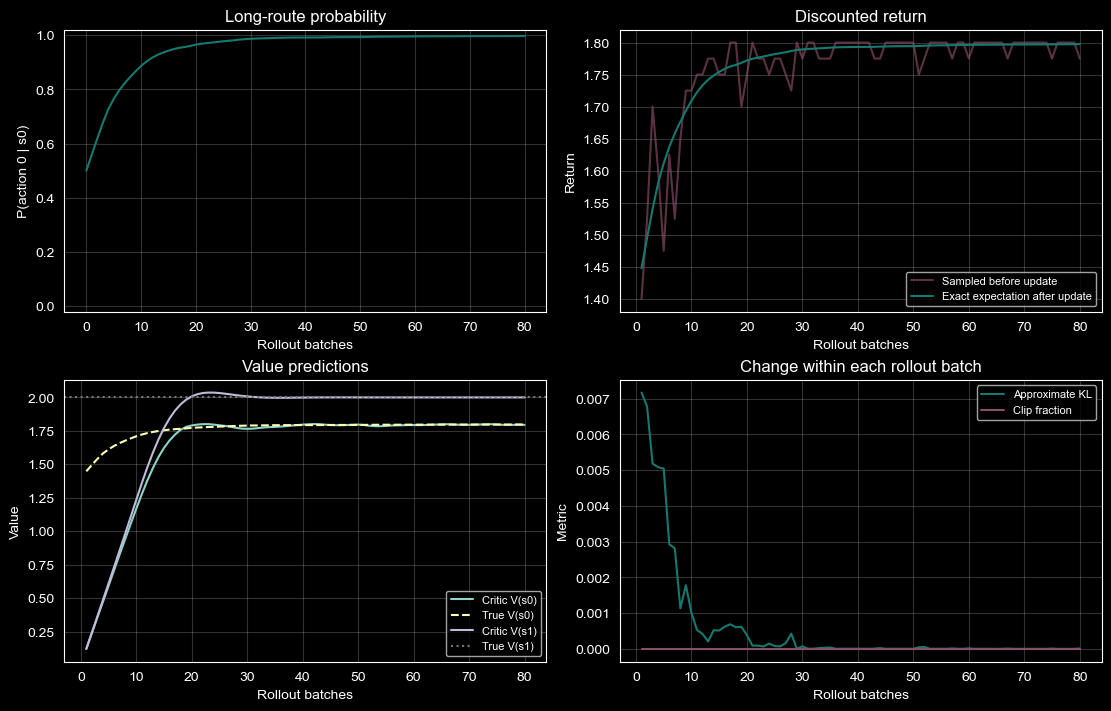

In [11]:
updates = [row["update"] for row in history]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
axes[0, 0].plot([0] + updates, [initial_stats["p_long"]] +
               [row["p_long"] for row in history], color="#16796f")
axes[0, 0].set(title="Long-route probability", xlabel="Rollout batches",
               ylabel="P(action 0 | s0)", ylim=(-0.02, 1.02))
axes[0, 1].plot(updates, [row["sample_return"] for row in history],
               label="Sampled before update", color="#8b4e68", alpha=0.65)
axes[0, 1].plot(updates, [row["expected_return"] for row in history],
               label="Exact expectation after update", color="#16796f")
axes[0, 1].set(title="Discounted return", xlabel="Rollout batches", ylabel="Return")
axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(updates, [row["value_s0"] for row in history], label="Critic V(s0)")
axes[1, 0].plot(updates, [row["expected_return"] for row in history],
               "--", label="True V(s0)")
axes[1, 0].plot(updates, [row["value_s1"] for row in history], label="Critic V(s1)")
axes[1, 0].axhline(2, linestyle=":", color="#777777", label="True V(s1)")
axes[1, 0].set(title="Value predictions", xlabel="Rollout batches", ylabel="Value")
axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(updates, [row["approx_kl"] for row in history],
               label="Approximate KL", color="#16796f")
axes[1, 1].plot(updates, [row["clip_fraction"] for row in history],
               label="Clip fraction", color="#8b4e68")
axes[1, 1].set(title="Change within each rollout batch",
               xlabel="Rollout batches", ylabel="Metric")
axes[1, 1].legend(fontsize=8)
for ax in axes.flat:
    ax.grid(alpha=0.2)
plt.show()

## 12. 自动验证关键行为

验证 GAE 边界、四种 clip 分支、目标无梯度、实际参数变化、
样本整行配对、KL 停止与完整冻结评估。
“这份配置能运行”不等于“任意参数都收敛”，更不替代自己阅读和复跑。
修改配置后若训练结果检查失败，应读取实际输出，而不是删除断言。

In [12]:
checks = []
def check(name, condition):
    assert condition, name
    checks.append(name)

check("GAE teaching example", torch.allclose(example_advantages, torch.tensor([-0.3, 2.0])))
for lam_value, expected in [(0.0, [-1.2, 2.0]), (1.0, [0.6, 2.0])]:
    got = compute_gae(torch.tensor([0.0, 4.0]), torch.tensor([3.0, 2.0]),
                      torch.tensor([2.0, 99.0]), torch.tensor([False, True]),
                      torch.tensor([False, True]), lam=lam_value)
    check(f"GAE lambda={lam_value}", torch.allclose(got, torch.tensor(expected)))
for term, expected in [(False, 0.35), (True, -1.0)]:
    got = compute_gae(torch.tensor([0.0, 100.0]), torch.tensor([1.0, 0.0]),
                      torch.tensor([1.5, 0.0]), torch.tensor([term, True]),
                      torch.tensor([True, True]))
    check(f"terminal/truncation mask {term}",
          torch.allclose(got, torch.tensor([expected, 100.0])))

for r, a, expected, gradient in [(1.4, .4, .48, 0), (.6, .4, .24, -.4),
                                  (.6, -.4, -.32, 0), (1.4, -.4, -.56, .4)]:
    ratio = torch.tensor(r, dtype=torch.float64, requires_grad=True)
    objective = torch.minimum(ratio * a, ratio.clamp(.8, 1.2) * a)
    (-objective).backward()
    check(f"clip value {r}/{a}", math.isclose(objective.item(), expected, abs_tol=1e-12))
    check(f"clip gradient {r}/{a}", math.isclose(ratio.grad.item(), gradient, abs_tol=1e-12))

check("sample collection does not train", all(
    torch.equal(demo_before_collect[k], v)
    for k, v in demo_after_collect.items()))
check("batch has 32 full episodes", len(demo_returns) == episodes_per_batch)
check("batch transition count", episodes_per_batch <= len(demo_batch["actions"]) <= 2 * episodes_per_batch)
check("all sampled trajectories terminate", all(path[-1][4] for path in demo_trajectories))
check("actual s1 actions reach terminal reward", all(
    len(path) == 1 or path[1][0] == 1 and path[1][2] == 2.0
    for path in demo_trajectories))
check("saved targets and probabilities have no gradient", all(
    not demo_batch[name].requires_grad for name in
    ("old_log_probs", "old_values", "raw_advantages", "actor_weights", "targets")))
check("target uses raw GAE", torch.equal(
    demo_batch["targets"], demo_batch["old_values"] + demo_batch["raw_advantages"]))
check("initial ratio equals one", math.isclose(demo_initial_metrics["ratio_mean"], 1.0))

gradient_model = ActorCritic()
gradient_loss, _ = compute_losses(gradient_model, demo_batch)
gradient_loss.backward()
check("Actor receives nonzero gradient", gradient_model.actor.weight.grad.abs().sum().item() > 0)
check("Critic receives nonzero gradient", gradient_model.critic.weight.grad.abs().sum().item() > 0)
check("update changes parameters", any(
    not torch.equal(demo_before_collect[k], v) for k, v in demo_model.state_dict().items()))

order = torch.arange(len(demo_batch["actions"]) - 1, -1, -1)
shuffled = {name: value[order] for name, value in demo_batch.items()}
loss_a, _ = compute_losses(demo_model, demo_batch)
loss_b, _ = compute_losses(demo_model, shuffled)
check("whole-row permutation preserves loss", torch.allclose(loss_a, loss_b, atol=1e-6))

gate_model = ActorCritic()
gate_optimizer = torch.optim.Adam(gate_model.parameters(), lr=learning_rate)
gate_logs, _, gate_stopped = update_batch(
    gate_model, gate_optimizer, demo_batch, kl_limit=1e-8)
check("KL threshold stops further updates", gate_stopped and len(gate_logs) == 1)
check("all 80 batches recorded", len(history) == num_updates)
check("each batch performs finite updates", all(0 < row["optimizer_steps"] <= update_epochs for row in history))
check("fresh episodes each batch", total_episodes == num_updates * episodes_per_batch)
check("probability improves", final_stats["p_long"] > 0.95)
check("Critic tracks s0", abs(final_stats["value_s0"] - final_stats["expected_return"]) < 0.15)
check("Critic tracks s1", abs(final_stats["value_s1"] - 2.0) < 0.15)
check("training metrics finite", all(
    math.isfinite(row[name]) for row in history for name in
    ("actor_loss", "critic_loss", "entropy", "approx_kl")))
check("evaluation count", len(eval_results) == eval_episodes)
check("evaluation parameter freeze", all(
    torch.equal(before_eval[k], v) for k, v in model.state_dict().items()))
check("all evaluation paths terminate", all(path[-1][4] for _, path in eval_results))
check("greedy path takes long route", len(greedy_trajectory) == 2 and greedy_trajectory[0][1] == 0)
check("greedy path fully terminates", greedy_trajectory[1][0] == 1 and greedy_trajectory[-1][4])
check("greedy discounted return", math.isclose(greedy_return, 1.8))
check("sample mean agrees with route counts",
      math.isclose(eval_mean, 1 + 0.8 * eval_long_count / eval_episodes, abs_tol=1e-12))
print(f"PASS {len(checks)} checks")
result = {"checks": checks, "initial": initial_stats, "final": final_stats,
          "episodes": total_episodes, "environment_steps": total_steps,
          "optimizer_steps": total_optimizer_steps,
          "evaluation_long_count": eval_long_count, "evaluation_count": eval_episodes,
          "evaluation_mean": eval_mean, "greedy_return": greedy_return,
          "greedy_trajectory": greedy_trajectory}
print("RESULT_JSON=" + json.dumps(result, ensure_ascii=False))

PASS 40 checks
RESULT_JSON={"checks": ["GAE teaching example", "GAE lambda=0.0", "GAE lambda=1.0", "terminal/truncation mask False", "terminal/truncation mask True", "clip value 1.4/0.4", "clip gradient 1.4/0.4", "clip value 0.6/0.4", "clip gradient 0.6/0.4", "clip value 0.6/-0.4", "clip gradient 0.6/-0.4", "clip value 1.4/-0.4", "clip gradient 1.4/-0.4", "sample collection does not train", "batch has 32 full episodes", "batch transition count", "all sampled trajectories terminate", "actual s1 actions reach terminal reward", "saved targets and probabilities have no gradient", "target uses raw GAE", "initial ratio equals one", "Actor receives nonzero gradient", "Critic receives nonzero gradient", "update changes parameters", "whole-row permutation preserves loss", "KL threshold stops further updates", "all 80 batches recorded", "each batch performs finite updates", "fresh episodes each batch", "probability improves", "Critic tracks s0", "Critic tracks s1", "training metrics finite", "ev

## 参考与实现范围

概率比分母、clip 目标、GAE-return 和 KL 监测参考官方实现；
为教学清晰使用本项目已有环境、独立线性分支与全批更新，不照搬整个工程。
仅包含离散动作 PPO 的最小训练闭环；没有多智能体、连续控制或 LLM 后训练。

- OpenAI Spinning Up：PPO-Clip 与 GAE。
- Stable-Baselines3：PPO 的 old_log_prob/returns 与 rollout buffer 的 GAE。
- PyTorch 2.11：Categorical、no_grad、Adam、clip_grad_norm_。

系数与训练曲线属于当前环境和配置，不能推出所有任务的收敛保证。